# 제8장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch08


## 8.11 의사결정트리 깊이와 가지 분기 해석

트리 깊이에 따른 훈련·검증 차이와 실제 분기 조건을 연결한다.

구조 그림은 깊이 2의 별도 트리다. 조건이 참이면 왼쪽 자식, 거짓이면 오른쪽 자식으로 내려간다. value는 해당 훈련 노드의 클래스 분포다.

주의: 깊이 비교는 검증을 통한 모델 선택이다. 노드의 훈련 분포가 새로운 모집단의 확률을 그대로 의미하지는 않는다.

In [2]:
%run sec_11_tree_depth.py

{
  "validation_n": 54,
  "comparison": [
    {
      "depth_label": "1",
      "nodes": 3,
      "train_accuracy": 0.6612903225806451,
      "validation_accuracy": 0.6111111111111112
    },
    {
      "depth_label": "2",
      "nodes": 7,
      "train_accuracy": 0.9354838709677419,
      "validation_accuracy": 0.8888888888888888
    },
    {
      "depth_label": "3",
      "nodes": 13,
      "train_accuracy": 0.9919354838709677,
      "validation_accuracy": 0.9629629629629629
    },
    {
      "depth_label": "4",
      "nodes": 15,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9629629629629629
    },
    {
      "depth_label": "6",
      "nodes": 15,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9629629629629629
    },
    {
      "depth_label": "None",
      "nodes": 15,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9629629629629629
    }
  ]
}


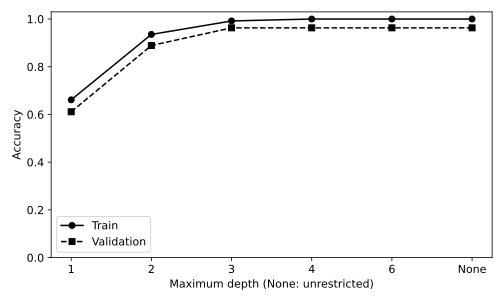

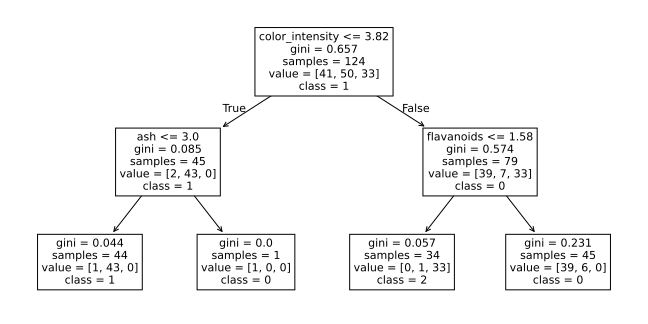

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/tree_depth.svg"))
display(SVG(filename="results/tree_structure.svg"))

### 확인 과제

한 테스트 행을 선택해 각 분기 조건을 대입하고 도달 잎의 예측을 predict와 비교한다.

## 8.12 앙상블 비교와 테스트 순열 중요도

서로 다른 앙상블을 동일 분할에서 비교하고 열을 섞을 때 예측 성능이 얼마나 떨어지는지 본다.

막대는 정확도 감소의 반복 평균이고 오차 막대는 반복 표준편차다. 신뢰구간이 아니며 음수가 나올 수도 있다.

주의: 테스트 중요도로 특성을 선택하면 이 테스트는 모델 개발에 사용된 것이 된다. 다음 모델의 최종 성능은 새로운 홀드아웃이 필요하다.

In [4]:
%run sec_12_ensemble_importance.py

{
  "test_n": 54,
  "accuracy": {
    "RandomForest": 1.0,
    "GradientBoosting": 0.9629629629629629
  }
}


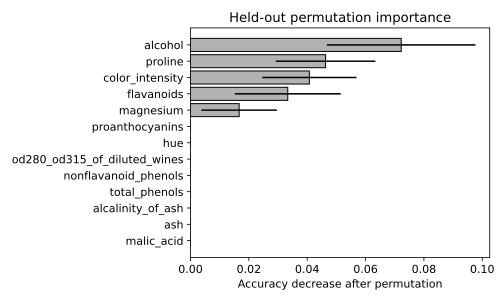

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/ensemble_importance.svg"))

### 확인 과제

상관된 두 특성이 중요도를 나누어 가질 수 있는 이유와 노드 불순도 중요도와의 차이를 설명한다.